In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# All six cities
cities = [
    "delhi",
    "hyderabad",
    "bengaluru",
    "chennai",
    "mumbai",
    "pune"
]

# Load each city's processed datasets
city_data = {}

for city in cities:
    folder = Path("../data/processed") / city

    city_data[city] = {
        "route_profile": pd.read_csv(folder / "route_profile.csv"),
        "hourly_trips": pd.read_csv(folder / "hourly_trip_counts.csv")
    }

    print(f"\n{city.upper()}")
    print("Route Profile:", city_data[city]["route_profile"].shape)
    print("Hourly Trips:", city_data[city]["hourly_trips"].shape)

print("\nAll six cities loaded successfully!")


DELHI
Route Profile: (2403, 5)
Hourly Trips: (26444, 3)

HYDERABAD
Route Profile: (1031, 6)
Hourly Trips: (8865, 3)

BENGALURU
Route Profile: (4434, 7)
Hourly Trips: (21805, 3)

CHENNAI
Route Profile: (4611, 7)
Hourly Trips: (21907, 3)

MUMBAI
Route Profile: (1609, 7)
Hourly Trips: (18403, 3)

PUNE
Route Profile: (628, 7)
Hourly Trips: (4543, 3)

All six cities loaded successfully!


In [5]:
for city in cities:
    print("\n" + "=" * 45)
    print(city.upper())
    print("=" * 45)

    route_df = city_data[city]["route_profile"]
    hourly_df = city_data[city]["hourly_trips"]

    print("\nRoute Profile Columns:")
    print(route_df.columns.tolist())

    print("\nMissing Values:")
    print(route_df.isnull().sum())

    print("\nDuplicate Route IDs:")
    print(route_df["route_id"].duplicated().sum())

    print("\nRoute Statistics:")
    print(route_df.select_dtypes(include="number").describe())

    print("\nDuplicate Hourly Records:")
    print(hourly_df.duplicated().sum())


DELHI

Route Profile Columns:
['route_id', 'route_short_name', 'route_long_name', 'total_trips', 'total_stops']

Missing Values:
route_id               0
route_short_name    2403
route_long_name        0
total_trips            0
total_stops            0
dtype: int64

Duplicate Route IDs:
0

Route Statistics:
           route_id  route_short_name  total_trips  total_stops
count   2403.000000               0.0  2403.000000  2403.000000
mean    5172.839367               NaN    37.200583    41.055347
std     3548.876465               NaN    41.009652    17.922021
min        1.000000               NaN     1.000000     2.000000
25%     1533.000000               NaN    10.000000    30.000000
50%     5385.000000               NaN    23.000000    42.000000
75%     5985.500000               NaN    47.000000    52.000000
max    10670.000000               NaN   318.000000   197.000000

Duplicate Hourly Records:
0

HYDERABAD

Route Profile Columns:
['route_id', 'route_long_name', 'agency_id', 'rou

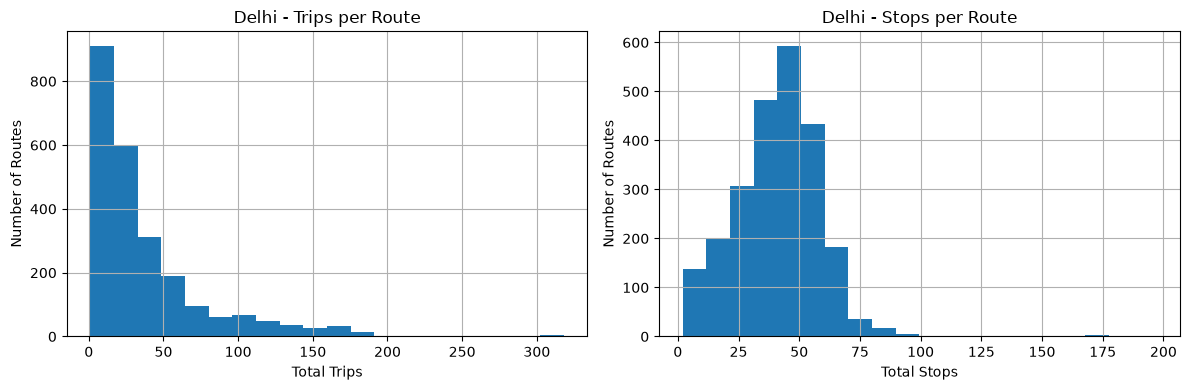

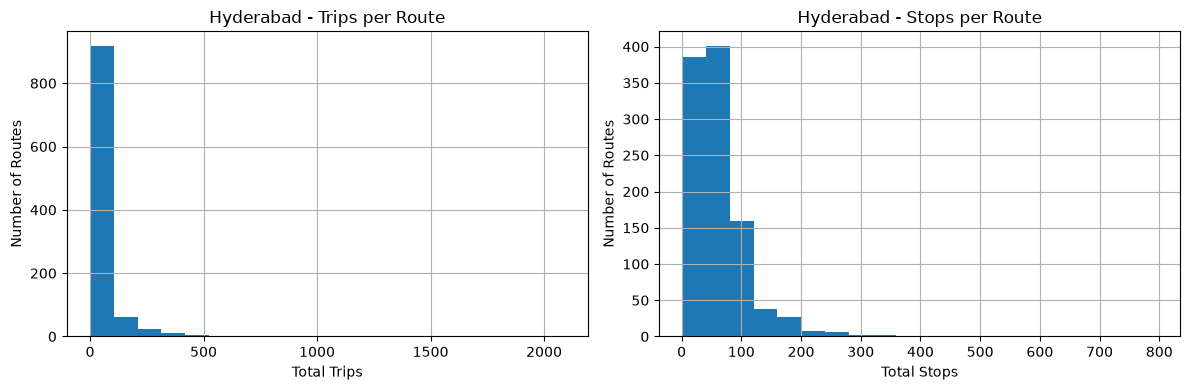

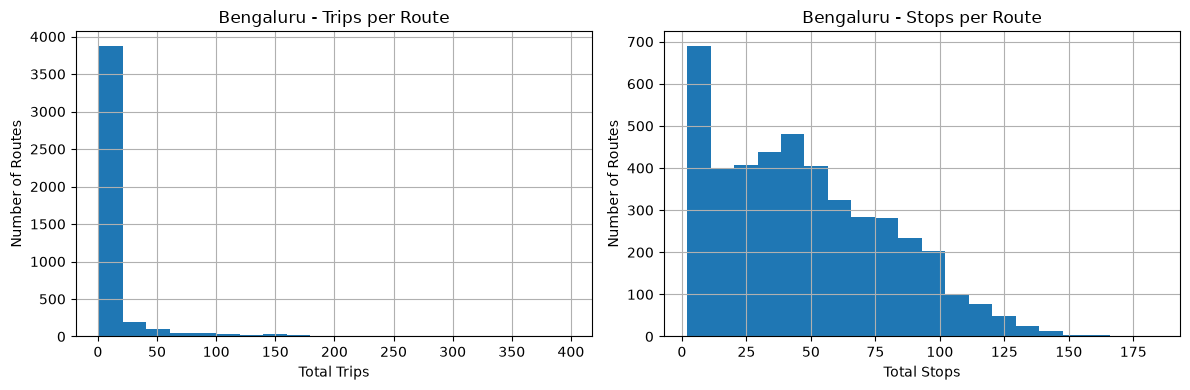

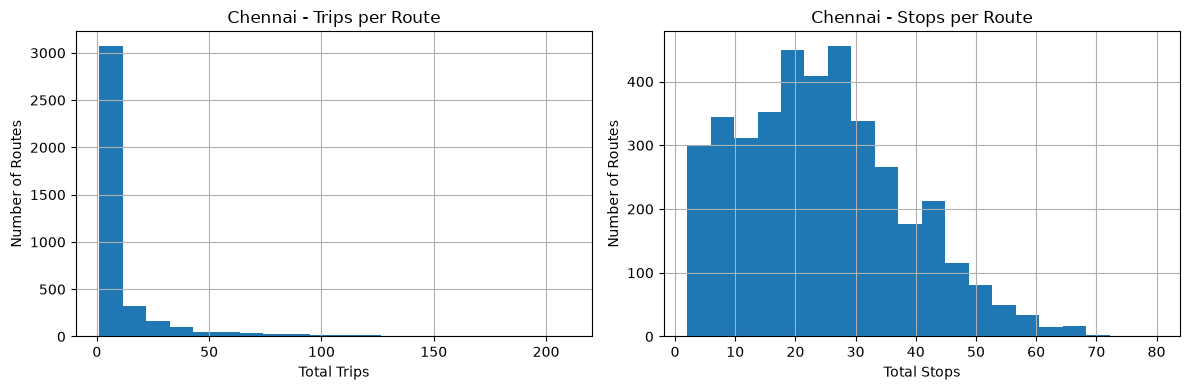

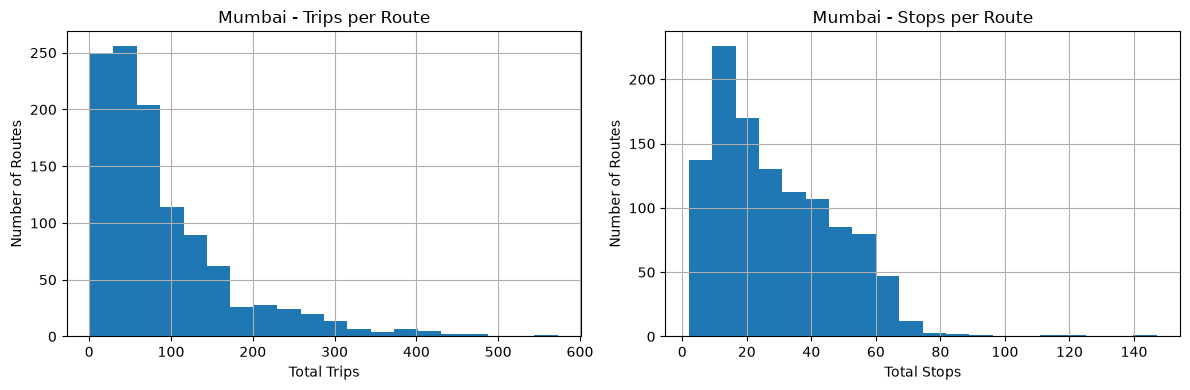

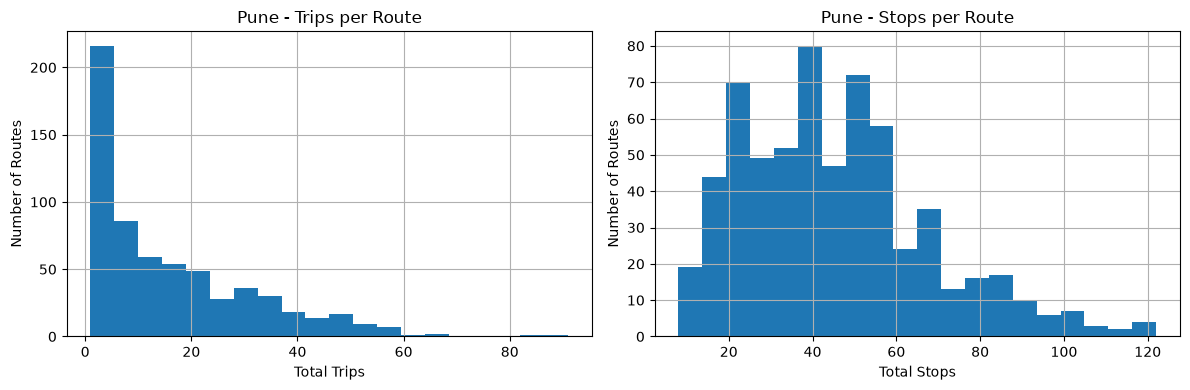

In [6]:
for city in cities:
    route_df = city_data[city]["route_profile"]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    route_df["total_trips"].dropna().hist(ax=axes[0], bins=20)
    axes[0].set_title(f"{city.title()} - Trips per Route")
    axes[0].set_xlabel("Total Trips")
    axes[0].set_ylabel("Number of Routes")

    route_df["total_stops"].dropna().hist(ax=axes[1], bins=20)
    axes[1].set_title(f"{city.title()} - Stops per Route")
    axes[1].set_xlabel("Total Stops")
    axes[1].set_ylabel("Number of Routes")

    plt.tight_layout()
    plt.show()

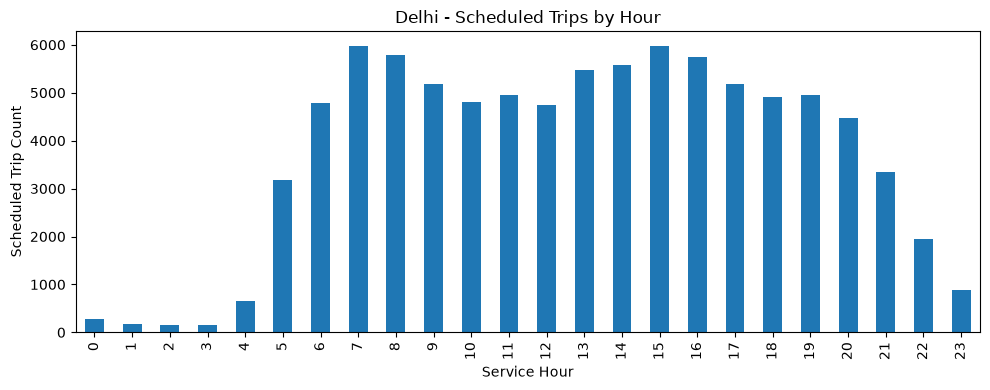


DELHI
Highest service hour: 15
Highest scheduled trips: 5982
Lowest service hour: 2
Lowest scheduled trips: 162


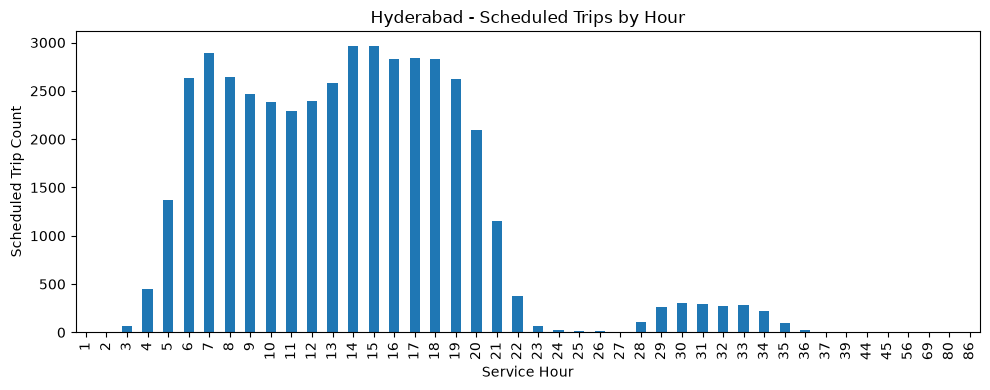


HYDERABAD
Highest service hour: 15
Highest scheduled trips: 2968
Lowest service hour: 1
Lowest scheduled trips: 1


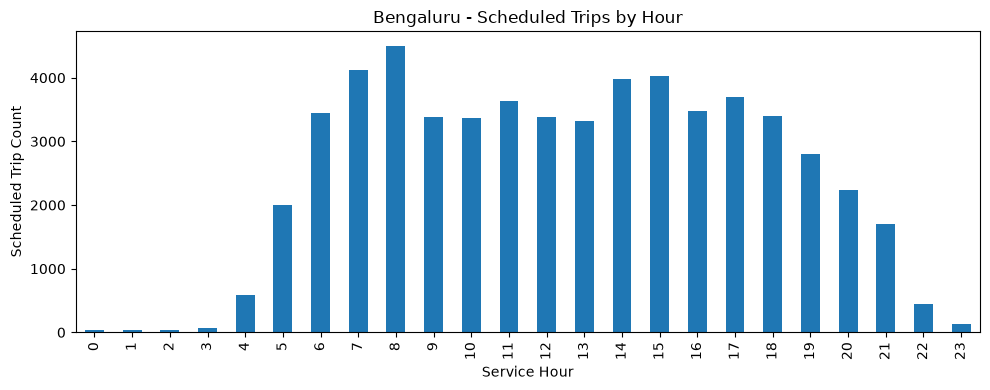


BENGALURU
Highest service hour: 8
Highest scheduled trips: 4504
Lowest service hour: 2
Lowest scheduled trips: 31


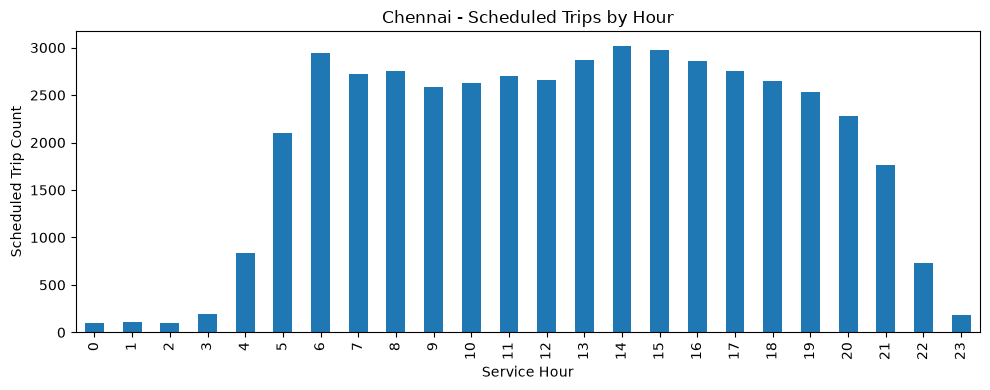


CHENNAI
Highest service hour: 14
Highest scheduled trips: 3021
Lowest service hour: 2
Lowest scheduled trips: 103


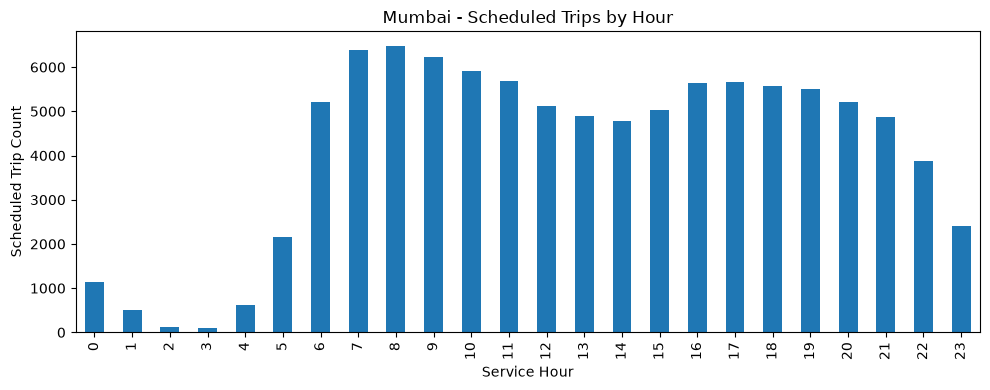


MUMBAI
Highest service hour: 8
Highest scheduled trips: 6485
Lowest service hour: 3
Lowest scheduled trips: 110


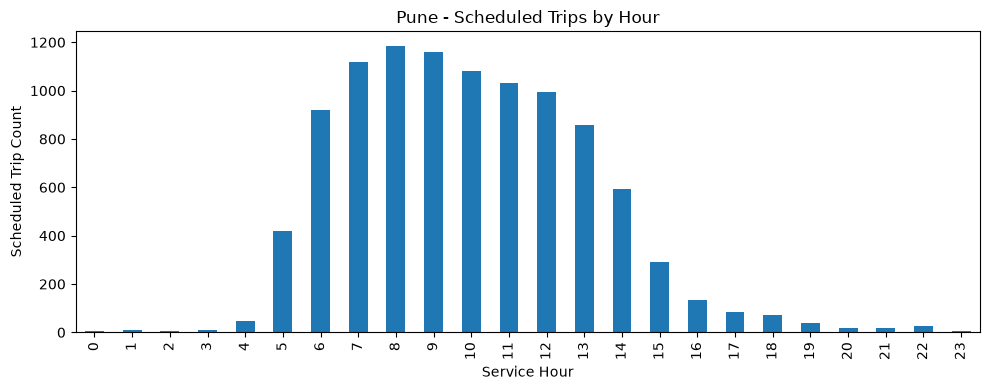


PUNE
Highest service hour: 8
Highest scheduled trips: 1186
Lowest service hour: 23
Lowest scheduled trips: 6


In [7]:
for city in cities:
    hourly_df = city_data[city]["hourly_trips"]

    hourly_summary = (
        hourly_df.groupby("departure_service_hour")["trip_count"]
        .sum()
        .sort_index()
    )

    plt.figure(figsize=(10, 4))
    hourly_summary.plot(kind="bar")

    plt.title(f"{city.title()} - Scheduled Trips by Hour")
    plt.xlabel("Service Hour")
    plt.ylabel("Scheduled Trip Count")
    plt.tight_layout()
    plt.show()

    print(f"\n{city.upper()}")
    print("Highest service hour:", hourly_summary.idxmax())
    print("Highest scheduled trips:", hourly_summary.max())
    print("Lowest service hour:", hourly_summary.idxmin())
    print("Lowest scheduled trips:", hourly_summary.min())

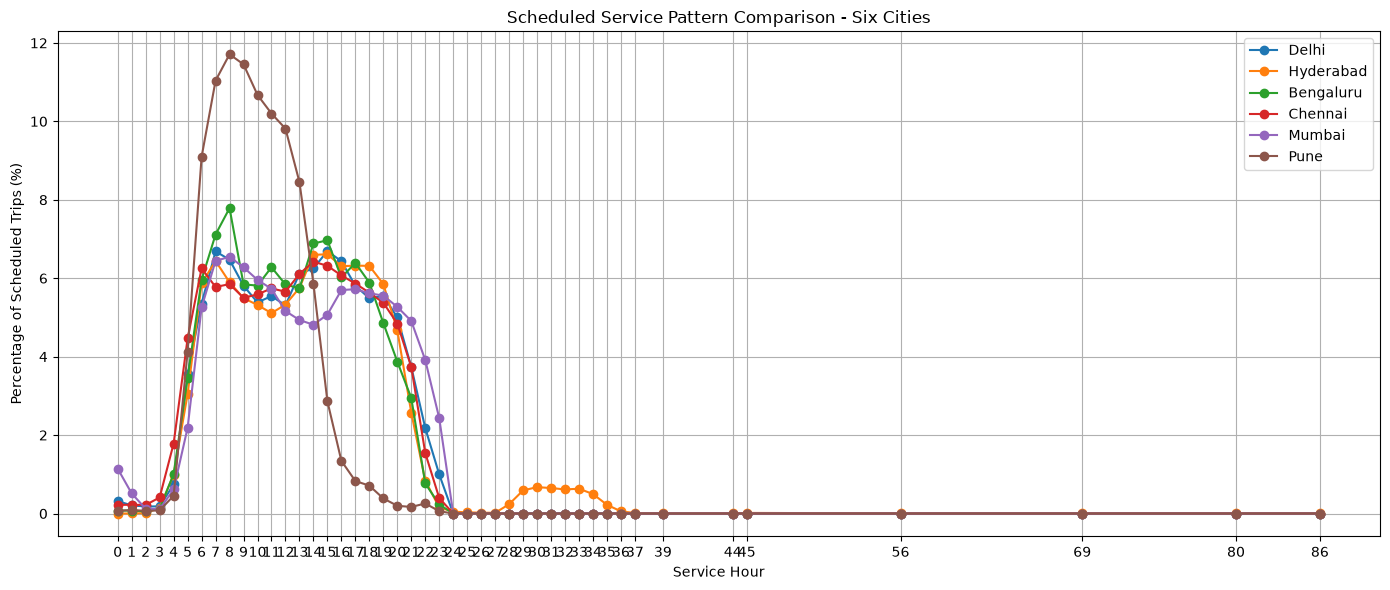

Hourly Service Comparison (%)


,delhi,hyderabad,bengaluru,chennai,mumbai,pune
departure_service_hour,,,,,,
0,0.32,0.00,0.07,0.22,1.14,0.07
1,0.21,0.00,0.08,0.22,0.51,0.09
2,0.18,0.01,0.05,0.22,0.12,0.07
3,0.18,0.15,0.12,0.41,0.11,0.08
4,0.74,0.99,1.01,1.79,0.61,0.45
5,3.55,3.05,3.45,4.47,2.19,4.13
6,5.35,5.87,5.96,6.25,5.26,9.09
7,6.69,6.44,7.11,5.78,6.44,11.04
8,6.47,5.90,7.79,5.85,6.55,11.71


In [8]:

hourly_comparison = {}

for city in cities:
    hourly_df = city_data[city]["hourly_trips"]

    hourly_summary = (
        hourly_df.groupby("departure_service_hour")["trip_count"]
        .sum()
        .sort_index()
    )

    # Convert trip counts into percentages
    hourly_percentage = (
        hourly_summary / hourly_summary.sum()
    ) * 100

    hourly_comparison[city] = hourly_percentage

# Combine all cities into one DataFrame
comparison_df = pd.DataFrame(hourly_comparison).fillna(0)

# Display comparison chart
plt.figure(figsize=(14, 6))

for city in comparison_df.columns:
    plt.plot(
        comparison_df.index,
        comparison_df[city],
        marker="o",
        label=city.title()
    )

plt.title("Scheduled Service Pattern Comparison - Six Cities")
plt.xlabel("Service Hour")
plt.ylabel("Percentage of Scheduled Trips (%)")
plt.xticks(comparison_df.index)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Display comparison table
print("Hourly Service Comparison (%)")
display(comparison_df.round(2))


In [9]:

for city in cities:
    hourly_df = city_data[city]["hourly_trips"]

    unusual_hours = hourly_df[
        (hourly_df["departure_service_hour"] < 0) |
        (hourly_df["departure_service_hour"] > 23)
    ]

    print("\n" + "=" * 40)
    print(city.upper())
    print("=" * 40)

    print("Unusual service hour records:")
    print(unusual_hours.to_string(index=False))

    print("Total unusual records:", len(unusual_hours))



DELHI
Unusual service hour records:
Empty DataFrame
Columns: [route_id, departure_service_hour, trip_count]
Index: []
Total unusual records: 0

HYDERABAD
Unusual service hour records:
  route_id  departure_service_hour  trip_count
         1                      27           1
         1                      28           7
         1                      29           1
         1                      30           1
         1                      31           4
         1                      32           3
         1                      33           2
         1                      34           1
        10                      29           1
        10                      30           1
        10                      32           2
        10                      33           1
        10                      34           1
      100H                      30           1
      100H                      31           1
      100H                      32           1
      100H      

In [10]:

for city in cities:
    hourly_df = city_data[city]["hourly_trips"]

    print("\n", "=" * 40)
    print(city.upper())
    print("=" * 40)

    print("Total records:", len(hourly_df))
    print("Minimum service hour:",
          hourly_df["departure_service_hour"].min())
    print("Maximum service hour:",
          hourly_df["departure_service_hour"].max())

    unusual = hourly_df[
        hourly_df["departure_service_hour"] > 23
    ]

    print("Records above hour 23:", len(unusual))
    print("Unusual hours:",
          sorted(unusual["departure_service_hour"].unique().tolist()))



DELHI
Total records: 26444
Minimum service hour: 0
Maximum service hour: 23
Records above hour 23: 0
Unusual hours: []

HYDERABAD
Total records: 8865
Minimum service hour: 1
Maximum service hour: 86
Records above hour 23: 873
Unusual hours: [24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 39, 44, 45, 56, 69, 80, 86]

BENGALURU
Total records: 21805
Minimum service hour: 0
Maximum service hour: 23
Records above hour 23: 0
Unusual hours: []

CHENNAI
Total records: 21907
Minimum service hour: 0
Maximum service hour: 23
Records above hour 23: 0
Unusual hours: []

MUMBAI
Total records: 18403
Minimum service hour: 0
Maximum service hour: 23
Records above hour 23: 0
Unusual hours: []

PUNE
Total records: 4543
Minimum service hour: 0
Maximum service hour: 23
Records above hour 23: 0
Unusual hours: []


In [11]:

hyd = city_data["HYDERABAD"]["hourly_trips"]

print("Records with service hours above 37:")
display(
    hyd[hyd["departure_service_hour"] > 37]
    .sort_values("departure_service_hour")
)

print("\nHighest service hours and trip counts:")
display(
    hyd.groupby("departure_service_hour")["trip_count"]
    .sum()
    .sort_index()
    .tail(15)
)


KeyError: 'HYDERABAD'

In [12]:
print(city_data.keys())

dict_keys(['delhi', 'hyderabad', 'bengaluru', 'chennai', 'mumbai', 'pune'])


In [13]:
hyd = city_data["hyderabad"]["hourly_trips"]

print("Records with service hours above 37:")

display(
    hyd[hyd["departure_service_hour"] > 37]
    .sort_values("departure_service_hour")
)

print("\nHighest service hours and trip counts:")

display(
    hyd.groupby("departure_service_hour")["trip_count"]
    .sum()
    .sort_index()
    .tail(15)
)

Records with service hours above 37:


,route_id,departure_service_hour,trip_count
399,10H,39,1
400,10H,44,2
401,10H,45,2
3024,216,45,1
3301,219,45,1
3536,222P,45,2
6613,459,45,1
3537,222P,56,2
3538,222P,69,2
3539,222P,80,2



Highest service hours and trip counts:


departure_service_hour
30    302
31    292
32    276
33    284
34    223
35    100
36     25
37      6
39      1
44      2
45      7
56      2
69      2
80      2
86      2
Name: trip_count, dtype: int64

In [14]:
hyd = city_data["hyderabad"]["hourly_trips"]

display(
    hyd[hyd["departure_service_hour"] > 47]
    .sort_values("departure_service_hour")
)

,route_id,departure_service_hour,trip_count
3537,222P,56,2
3538,222P,69,2
3539,222P,80,2
3540,222P,86,2


PEAK AND OFF-PEAK SERVICE COMPARISON (%)


period,Afternoon,Evening,Morning,Night
delhi,36.35,25.59,29.70,8.36
hyderabad,36.01,25.76,32.09,6.14
bengaluru,37.73,23.96,32.52,5.79
chennai,36.32,25.45,28.97,9.26
mumbai,31.41,27.07,30.48,11.04
pune,38.54,2.29,53.97,5.20


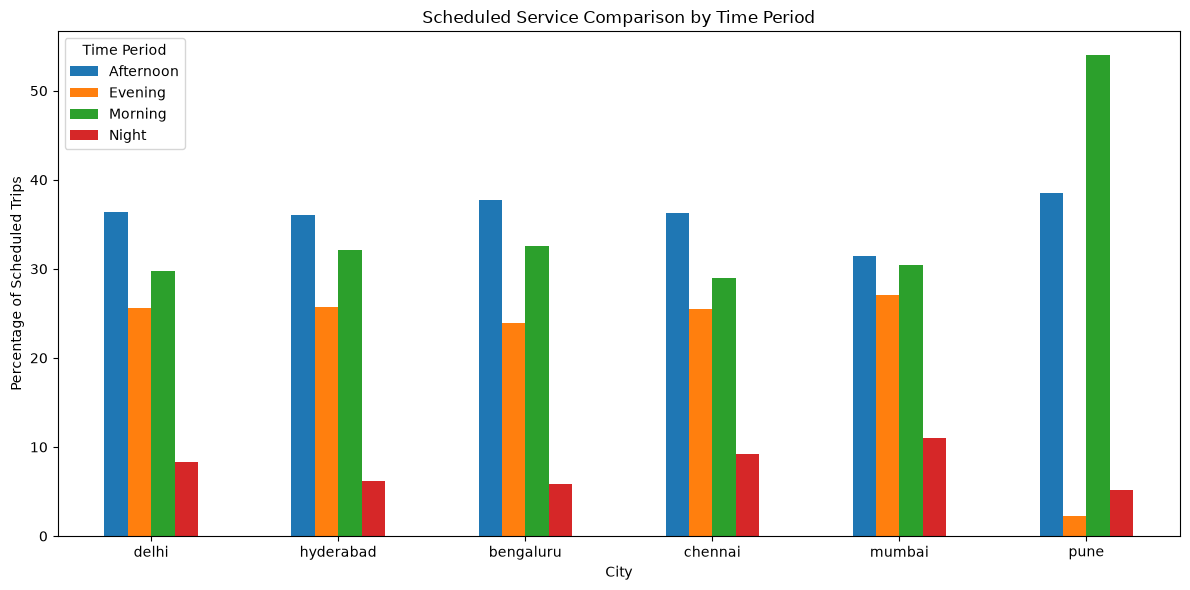

In [15]:

period_results = {}

for city in cities:
    hourly_df = city_data[city]["hourly_trips"].copy()

    # Keep valid service hours for analysis
    hourly_df = hourly_df[
        (hourly_df["departure_service_hour"] >= 0) &
        (hourly_df["departure_service_hour"] <= 47)
    ].copy()

    # Convert extended GTFS hours to clock hours
    hourly_df["hour"] = (
        hourly_df["departure_service_hour"] % 24
    )

    def get_period(hour):
        if 6 <= hour <= 10:
            return "Morning"
        elif 11 <= hour <= 16:
            return "Afternoon"
        elif 17 <= hour <= 21:
            return "Evening"
        else:
            return "Night"

    hourly_df["period"] = hourly_df["hour"].apply(get_period)

    summary = hourly_df.groupby("period")["trip_count"].sum()

    total = summary.sum()
    period_results[city] = (summary / total * 100)

# Comparison table
period_df = pd.DataFrame(period_results).T

print("PEAK AND OFF-PEAK SERVICE COMPARISON (%)")
display(period_df.round(2))

# Comparison chart
period_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Scheduled Service Comparison by Time Period")
plt.xlabel("City")
plt.ylabel("Percentage of Scheduled Trips")
plt.xticks(rotation=0)
plt.legend(title="Time Period")
plt.tight_layout()
plt.show()


In [16]:

print("FINAL EDA SUMMARY - SIX CITIES")
print("=" * 50)

for city in period_df.index:
    peak = period_df.loc[city].idxmax()
    lowest = period_df.loc[city].idxmin()

    print(f"\n{city.upper()}")
    print("Highest service period:", peak)
    print("Percentage:", period_df.loc[city, peak], "%")
    print("Lowest service period:", lowest)
    print("Percentage:", period_df.loc[city, lowest], "%")


FINAL EDA SUMMARY - SIX CITIES

DELHI
Highest service period: Afternoon
Percentage: 36.347365006208534 %
Lowest service period: Night
Percentage: 8.361952278142585 %

HYDERABAD
Highest service period: Afternoon
Percentage: 36.006149184564656 %
Lowest service period: Night
Percentage: 6.142500668389626 %

BENGALURU
Highest service period: Afternoon
Percentage: 37.73255411854208 %
Lowest service period: Night
Percentage: 5.790511100352721 %

CHENNAI
Highest service period: Afternoon
Percentage: 36.31687461474696 %
Lowest service period: Night
Percentage: 9.26307734818373 %

MUMBAI
Highest service period: Afternoon
Percentage: 31.41199031085991 %
Lowest service period: Night
Percentage: 11.03552684699233 %

PUNE
Highest service period: Morning
Percentage: 53.96919431279621 %
Lowest service period: Evening
Percentage: 2.2906793048973144 %
